## Setup

In [282]:
import pandas as panda
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = panda.read_csv('twine_mutation_dataset_clean.csv')


__________
## Gather Data for Both Targets

In [283]:
targets = ['fastest_lap_seconds', 'threshold_reached_at_seconds']

y = df[targets]
X = df.drop(columns=targets)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 3)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_train = panda.DataFrame(X_train, columns = X.columns)

X_train.head(1)

,allowed_slip_angle,allowed_yaw_rate,checkpoint_count,checkpoint_reward_per_lap,excessive_yaw_penalty_per_second,forward_progress_reward_per_second,lap_time_reward_at_target,lap_time_reward_scale,max_wall_contact_seconds,maximum_slip_angle,...,target_progress_reward_scale,time_penalty_per_second,wall_impact_penalty,wall_penalty_per_second,wall_ray_angle_power,wall_ray_center_distance,wall_ray_center_power,wall_ray_count,wall_ray_side_distance,human_lap_target_seconds
0,-0.195999,-0.377782,-0.982655,1.299763,0.283252,0.186087,-0.972511,0.352895,1.264059,0.46254,...,-0.87933,0.719665,-1.619808,0.356867,-0.586457,-0.704679,-1.275764,-0.312999,-0.992881,0.0


In [284]:
X_train.shape

(79, 21)

#### View PCA with default settings

[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227
 0.06436172 0.05604092 0.05311522 0.04615467 0.04420221 0.04244233
 0.03750852 0.03105435 0.02892523 0.02868929 0.02271438 0.02088698
 0.01839509 0.01421476 0.        ]
Total variance: 0.9999999999999999
Shape: (79, 21)


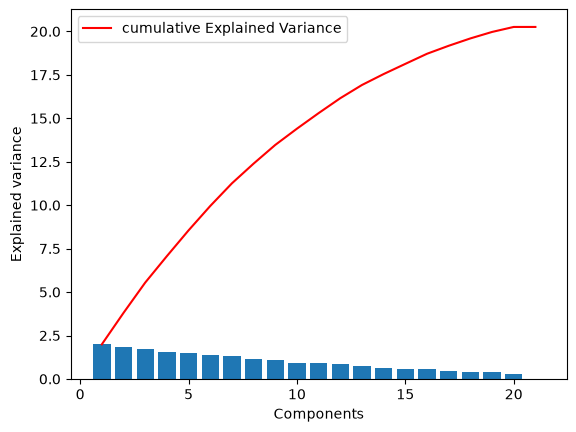

In [285]:
pca1 = PCA()
X_pca1 = pca1.fit_transform(X_train)

plt.bar(range(1,len(pca1.explained_variance_)+1), pca1.explained_variance_)
plt.ylabel('Explained variance')
plt.xlabel('Components')
plt.plot(range(1,len(pca1.explained_variance_)+1), np.cumsum(pca1.explained_variance_), c='red', label = "cumulative Explained Variance")
plt.legend(loc='upper left')

print(pca1.explained_variance_ratio_)
print('Total variance:', sum(pca1.explained_variance_ratio_))
print('Shape:', X_pca1.shape)

#### View PCA for 0.95 variance

[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227
 0.06436172 0.05604092 0.05311522 0.04615467 0.04420221 0.04244233
 0.03750852 0.03105435 0.02892523 0.02868929 0.02271438 0.02088698]
Total variance: 0.9673901491361756
Shape: (79, 18)


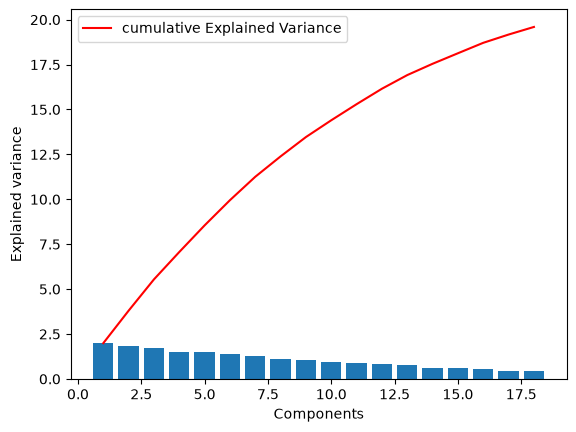

In [286]:
pca2 = PCA(0.95)
X_pca2 = pca2.fit_transform(X_train)

plt.bar(range(1,len(pca2.explained_variance_)+1), pca2.explained_variance_)
plt.ylabel('Explained variance')
plt.xlabel('Components')
plt.plot(range(1,len(pca2.explained_variance_)+1), np.cumsum(pca2.explained_variance_), c='red', label = "cumulative Explained Variance")
plt.legend(loc='upper left')

print(pca2.explained_variance_ratio_)
print('Total variance:', sum(pca2.explained_variance_ratio_))
print('Shape:', X_pca2.shape)

#### View PCA for n number of components, from 2 to 18

In [287]:
print("Every value given between brackets [] is how much information each component holds. \n")

for val in range(2,18):
    pcaWithComponents = PCA(n_components=val)
    X_pcaWithComponents = pcaWithComponents.fit_transform(X_train)
    print('Component count: ', val)
    print(pcaWithComponents.explained_variance_ratio_)
    print('Total variance:', sum(pcaWithComponents.explained_variance_ratio_))
    # print('Shape:', X_pcaWithComponents.shape)
    print()



Every value given between brackets [] is how much information each component holds. 

Component count:  2
[0.09831312 0.08934506]
Total variance: 0.1876581859260913

Component count:  3
[0.09831312 0.08934506 0.08599886]
Total variance: 0.27365704972485666

Component count:  4
[0.09831312 0.08934506 0.08599886 0.07521664]
Total variance: 0.3488736874527403

Component count:  5
[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794]
Total variance: 0.4220716237916536

Component count:  6
[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227 ]
Total variance: 0.491294320963222

Component count:  7
[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227
 0.06436172]
Total variance: 0.5556560426150048

Component count:  8
[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227
 0.06436172 0.05604092]
Total variance: 0.6116969599529832

Component count:  9
[0.09831312 0.08934506 0.08599886 0.07521664 0.07319794 0.0692227
 0.06436172 0.05604092 0.05311522]
To

__________
## Extract components

Using `pca2`, which was connected to the 0.95 variance parameter, might be best, so here we extract the components it found.

In [288]:
loadings = panda.DataFrame(pca2.components_.T, index = X.columns, columns = [f'PC{i+1}' for i in range(pca2.n_components_)])
print(loadings)

                                         PC1       PC2       PC3       PC4  \
allowed_slip_angle                  0.440364  0.275167 -0.010044  0.198934   
allowed_yaw_rate                    0.003697 -0.225345  0.200778  0.147585   
checkpoint_count                   -0.212409  0.281779 -0.234100  0.124790   
checkpoint_reward_per_lap          -0.025886 -0.353111 -0.370892 -0.208143   
excessive_yaw_penalty_per_second    0.109834  0.329385  0.156207 -0.438047   
forward_progress_reward_per_second  0.324280  0.070418  0.341141  0.003961   
lap_time_reward_at_target          -0.018597  0.056991 -0.180922 -0.334637   
lap_time_reward_scale              -0.399178  0.158920  0.083925  0.258847   
max_wall_contact_seconds            0.316594  0.292174  0.013262  0.111739   
maximum_slip_angle                  0.024028  0.358004 -0.294626 -0.067774   
slip_penalty_per_second            -0.185058 -0.023061  0.445238  0.022523   
target_progress_reward_scale       -0.176343 -0.031639  0.022435